In [1]:
import pandas as pd
import numpy as np
import os

In [5]:
os.chdir("../data")

# Applying custom functions and creating new columns

The `apply()` method is one of the most common methods of data preprocessing. It simplifies applying a function on each element in a pandas Series and each row or column in a pandas DataFrame. 

Let's first create experimenting DataFrame:

In [6]:
df = pd.DataFrame({'EmployeeName': ['Callen Dunkley', 'Sarah Rayner', 'Jeanette Sloan', 'Kaycee Acosta', 'Henri Conroy', 'Emma Peralta', 'Martin Butt', 'Alex Jensen', 'Kim Howarth', 'Jane Burnett'],
                    'Department': ['Accounting', 'Engineering', 'Engineering', 'HR', 'HR', 'HR', 'Data Science', 'Data Science', 'Accounting', 'Data Science'],
                    'HireDate': [2010, 2018, 2012, 2014, 2014, 2018, 2020, 2018, 2020, 2012],
                    'Sex': ['M', 'F', 'F', 'F', 'M', 'F', 'M', 'M', 'M', 'F'],
                    'Birthdate': ['04/09/1982', '14/04/1981', '06/05/1997', '08/01/1986', '10/10/1988', '12/11/1992', '10/04/1991', '16/07/1995', '08/10/1992', '11/10/1979'],
                    'Weight': [78, 80, 66, 67, 90, 57, 115, 87, 95, 57],
                    'Height': [176, 160, 169, 157, 185, 164, 195, 180, 174, 165],
                    'Kids': [2, 1, 0, 1, 1, 0, 2, 0, 3, 1]})
df.head()

,EmployeeName,Department,HireDate,Sex,Birthdate,Weight,Height,Kids
0,Callen Dunkley,Accounting,2010,M,04/09/1982,78,176,2
1,Sarah Rayner,Engineering,2018,F,14/04/1981,80,160,1
2,Jeanette Sloan,Engineering,2012,F,06/05/1997,66,169,0
3,Kaycee Acosta,HR,2014,F,08/01/1986,67,157,1
4,Henri Conroy,HR,2014,M,10/10/1988,90,185,1


Lambda functions are very useful for applying simple functions:

In [7]:
low = lambda x: x.lower()
df['Sex'] = df['Sex'].apply(low)
df

,EmployeeName,Department,HireDate,Sex,Birthdate,Weight,Height,Kids
0,Callen Dunkley,Accounting,2010,m,04/09/1982,78,176,2
1,Sarah Rayner,Engineering,2018,f,14/04/1981,80,160,1
2,Jeanette Sloan,Engineering,2012,f,06/05/1997,66,169,0
3,Kaycee Acosta,HR,2014,f,08/01/1986,67,157,1
4,Henri Conroy,HR,2014,m,10/10/1988,90,185,1
5,Emma Peralta,HR,2018,f,12/11/1992,57,164,0
6,Martin Butt,Data Science,2020,m,10/04/1991,115,195,2
7,Alex Jensen,Data Science,2018,m,16/07/1995,87,180,0
8,Kim Howarth,Accounting,2020,m,08/10/1992,95,174,3
9,Jane Burnett,Data Science,2012,f,11/10/1979,57,165,1


The above lambda function operates on a string by making all characters in the string lower. Then, with `apply()` method it is applied over the column *Sex* - a value (string) in each row is made lower. Notice that the "old" *Sex* column values are overwritten.

Let's now create a named function to be applied over *Height* column with `apply()` method and store it in a new column named *Height (in)*. By creating a new column we perserved height in *cm* and got height in *inches*.

In [8]:
def cm_to_feet(h):
    return np.round(h/30.48, 2)

In [9]:
df['Height (in)'] = df['Height'].apply(cm_to_feet)
df

,EmployeeName,Department,HireDate,Sex,Birthdate,Weight,Height,Kids,Height (in)
0,Callen Dunkley,Accounting,2010,m,04/09/1982,78,176,2,5.77
1,Sarah Rayner,Engineering,2018,f,14/04/1981,80,160,1,5.25
2,Jeanette Sloan,Engineering,2012,f,06/05/1997,66,169,0,5.54
3,Kaycee Acosta,HR,2014,f,08/01/1986,67,157,1,5.15
4,Henri Conroy,HR,2014,m,10/10/1988,90,185,1,6.07
5,Emma Peralta,HR,2018,f,12/11/1992,57,164,0,5.38
6,Martin Butt,Data Science,2020,m,10/04/1991,115,195,2,6.40
7,Alex Jensen,Data Science,2018,m,16/07/1995,87,180,0,5.91
8,Kim Howarth,Accounting,2020,m,08/10/1992,95,174,3,5.71
9,Jane Burnett,Data Science,2012,f,11/10/1979,57,165,1,5.41


<div class="alert alert-block alert-success">
<b>Task: </b>Let's assume that the HR team wants to send an invitation email that starts with a friendly greeting to all the employees (e.g., Hey, Sarah!). They asked you to create two columns for storing the employees' first and last names separately, making referring to the employees’ first name easy. 
</div>

In [ ]:
# solution

`apply()` method is used only over pandas Series or DataFrame rows/columns, but if you need to apply a function over the whole structure, use `applymap()`.

# Advanced pandas conditioning

When analyzing real-world datasets, we often need to select rows that satisfy multiple conditions or combine conditions to explore specific subsets of data. Pandas allows us to create complex filters using comparison operators, logical operators, and methods for working with strings and missing values. These techniques help us extract relevant information and answer more specific questions about our data.

In [10]:
df_subset = df[(df['Weight'] > 70) & (df['Height'] < 170)]
df_subset

,EmployeeName,Department,HireDate,Sex,Birthdate,Weight,Height,Kids,Height (in)
1,Sarah Rayner,Engineering,2018,f,14/04/1981,80,160,1,5.25


<div class="alert alert-block alert-warning">
<b>Example: </b>Create a new column based on a condition related to the BMI. Body mass index (BMI) is a measure of body fat based on height and weight that applies to adult men and women. Formula for calucating BMI is 
    <p>$BMI = \frac{\text{weight in kg}}{(\text{height in m})^2}$</p>
    <p>There are multiple categories made based on the BMI values, but to simplify we will use only <i>Overweight</i> if BMI is more than 25, otherwise <i>Normal</i> .</p>
</div>

In [11]:
df['BMI category'] = np.where(df['Weight']/(df['Height'] / 100)**2 >= 25, 'Overweight', 'Normal')
df

,EmployeeName,Department,HireDate,Sex,Birthdate,Weight,Height,Kids,Height (in),BMI category
0,Callen Dunkley,Accounting,2010,m,04/09/1982,78,176,2,5.77,Overweight
1,Sarah Rayner,Engineering,2018,f,14/04/1981,80,160,1,5.25,Overweight
2,Jeanette Sloan,Engineering,2012,f,06/05/1997,66,169,0,5.54,Normal
3,Kaycee Acosta,HR,2014,f,08/01/1986,67,157,1,5.15,Overweight
4,Henri Conroy,HR,2014,m,10/10/1988,90,185,1,6.07,Overweight
5,Emma Peralta,HR,2018,f,12/11/1992,57,164,0,5.38,Normal
6,Martin Butt,Data Science,2020,m,10/04/1991,115,195,2,6.40,Overweight
7,Alex Jensen,Data Science,2018,m,16/07/1995,87,180,0,5.91,Overweight
8,Kim Howarth,Accounting,2020,m,08/10/1992,95,174,3,5.71,Overweight
9,Jane Burnett,Data Science,2012,f,11/10/1979,57,165,1,5.41,Normal


# Pandas data types

When doing data analysis, it is important to make sure you are using the correct data types; otherwise you may get unexpected results or errors. In the case of pandas, it will correctly infer data types in many cases and you can move on with your analysis without any further thought on the topic. Sometimes, pandas infer column type (or *dtype*) as generic *object* dtype (similar to Python `str` type). Additionally, certain datasets or columns in the dataset require specific data types to be defined, to perform adequate operations on them. Therefore, we need to convert data to be able to continue our analysis.

In order to convert data types in pandas, there are three basic options:

- Use `dtype` parameter when creating or importing dataset
- Use `astype()` to force an appropriate dtype
- Create a custom function to convert the data
- Use specific pandas methods (will be described below)

## Numerical attributes

Usually pandas infer correct types for numerical attributes, but if it is not the case than it can be specified by using `astype(<type>)` (e.g., `<type>` is replaced with strings `'int32'`, `float64` etc.) on a working DataFrame or DataFrame column, or by passing DataFrame to `pandas.to_numeric()`.

Let's use the same data as previously.

In [12]:
df.dtypes

EmployeeName        str
Department          str
HireDate          int64
Sex                 str
Birthdate           str
Weight            int64
Height            int64
Kids              int64
Height (in)     float64
BMI category        str
dtype: object

The following line will change the type of all columns in the given DataFrame:

<code>df.astype('float64')</code>

Note that it returns a new DataFrame with the specified data type, so you need to assign the result to a variable to keep the changes.

To change the data types of specific columns, a dictionary with column names as keys and data types (built-in strings, objects etc.) as values can be forwarded, too.

In [13]:
df.astype({'Weight': 'float64'}).dtypes

EmployeeName        str
Department          str
HireDate          int64
Sex                 str
Birthdate           str
Weight          float64
Height            int64
Kids              int64
Height (in)     float64
BMI category        str
dtype: object

Or change column data type by choosing specific column directly from DataFrame.

In [14]:
df['Kids'].astype('int32').dtypes

dtype('int32')

<div class="alert alert-block alert-info">
    <b>Tip: </b>The conversion with <code>astype()</code> can be problematic when a non-numeric value(s) are included in the column. If we tried to use <code>astype()</code>, we would get an error. The <code>pd.to_numeric()</code> function can handle these values more gracefully. It provides parameter <code>errors</code> for control over raising of exceptions on invalid data.
</div>


## Categorical attributes

Categoricals are a pandas data type corresponding to categorical variables in statistics. They take on a limited, and usually fixed, number of possible values (categories) and they are ordered (e.g. 'strongly agree' vs 'agree' or 'first observation' vs. 'second observation'), by certain logic not lexically (e.g. one, two, three). Numerical operations (additions, divisions, etc.) are not possible on such data, but operations like sorting and max/min are possible.

As an example we will use DataFrame with one column `Grades`, which represents letter grading system.

In [15]:
df = pd.DataFrame(['A+', 'A', 'A-', 'B+', 'B', 'B-', 'C+', 'C', 'C-', 'D+', 'D'],
                  index=['excellent', 'excellent', 'excellent', 'good', 'good', 'good', 'ok', 'ok', 'ok', 'poor', 'poor'])
df.rename(columns={0: 'Grades'}, inplace=True)
df

,Grades
excellent,A+
excellent,A
excellent,A-
good,B+
good,B
good,B-
ok,C+
ok,C
ok,C-
poor,D+


Pandas will infer `Grades` dtype as `str`

In [16]:
df.dtypes

Grades    str
dtype: object

And we will be unabled to compare all grades better than `C` using comparison operation `>`:

In [17]:
df > 'C'

,Grades
excellent,False
excellent,False
excellent,False
good,False
good,False
good,False
ok,True
ok,False
ok,True
poor,True


It is not enough to specify only `'category'` type with `astype()` function, since we want certain order of grades (A+ > A > A- > ... > D+ > D). Observe the following: 

In [19]:
grades = df['Grades'].astype('category') # categories
grades

excellent    A+
excellent     A
excellent    A-
good         B+
good          B
good         B-
ok           C+
ok            C
ok           C-
poor         D+
poor          D
Name: Grades, dtype: category
Categories (11, str): ['A', 'A+', 'A-', 'B', ..., 'C+', 'C-', 'D', 'D+']

The order is not what we have expected. Therefore, we use `pandas.Categorical`:

In [22]:
df['Grades'] = pd.Categorical(df['Grades'].values,
                             categories=['D', 'D+', 'C-', 'C', 'C+', 'B-', 'B', 'B+', 'A-', 'A', 'A+'], # from smallest to largest
                             ordered=True) # ordered categories
df['Grades']

excellent    A+
excellent     A
excellent    A-
good         B+
good          B
good         B-
ok           C+
ok            C
ok           C-
poor         D+
poor          D
Name: Grades, dtype: category
Categories (11, str): ['D' < 'D+' < 'C-' < 'C' ... 'B+' < 'A-' < 'A' < 'A+']

In [23]:
df > 'C'

,Grades
excellent,True
excellent,True
excellent,True
good,True
good,True
good,True
ok,True
ok,False
ok,False
poor,False


<div class="alert alert-block alert-info">
<b>Note: </b>In the older versions of Python, it was possible to use:    
    <p><code>grades = df['Grades'].astype('category',
                             categories=['D', 'D+', 'C-', 'C', 'C+', 'B-', 'B', 'B+', 'A-', 'A', 'A+'],
                             ordered=True)</code></p>
    <p>Now, this would raise an error.</p>
    
</div>

# Concatenate, merge, join

<div class="alert alert-block alert-info">
<b>Tip: </b>This section provides very brief summary of ways for combining pandas data structures. For details visit <a href="https://pandas.pydata.org/docs/user_guide/merging.html">official tutorial</a>.
</div>

Create working DataFrames:

In [ ]:
df1 = pd.DataFrame({'key': ['b', 'b', 'a', 'c', 'a', 'a', 'b'], 
                 'data1': range(7)})
df2 = pd.DataFrame({'key': ['a', 'b', 'd'], 
                 'data2': range(3)})

Pandas provides various facilities for easily combining together Series or DataFrame:
- `pd.concat()` performs concatenation operations along an axis while performing optional set logic (union or intersection) of the indexes (if any) on the other axes (similar to `numpy.concatenate()`)
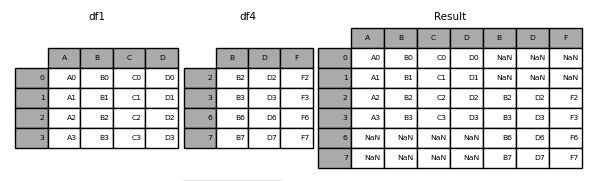

`pd.concat()` takes A SEQUENCE of objects (Series, DataFrames) and *concatenate* them.

In [ ]:
pd.concat([df1, df2])

- `pd.merge()` will perform standard database join operations based on other specific key column (similar to relational databases)

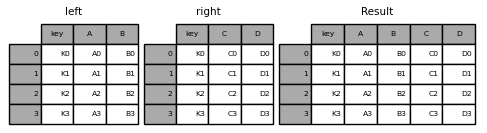

`pd.merge()` takes DATAFRAMES and can specify explicitly the join key with parameter `on`.

In [ ]:
pd.merge(df1, df2) # merge uses the overlapping column names as the keys by default or provided by parameter on

<div class="alert alert-block alert-success">
<b>Task: </b> What is the difference between the outputs of <code>pd.concat()</code> and <code>pd.merge()</code>? Discuss.
</div>

## Data Aggregation and Group Operations

An important part of data analysis is the process of grouping, summarizing, aggregating and calculating statistics about this data. For this, you have an option to use `groupby()` method.

First, create example DataFrame:

In [ ]:
df = pd.DataFrame({'key1': ['a', 'a', 'b', 'b', 'a'],
                   'key2': ['one', 'two', 'one', 'two', 'one'],
                   'data1': np.random.randn(5),
                   'data2': np.random.randn(5)})
df

`groupby()` will create a data structure, which cannot be seen as long as aggregation function isn't provided.

In [ ]:
grouped = df['data1'].groupby(df['key1'])
grouped # just to check

In [ ]:
print('Mean of data1 grouped by key1')
grouped.mean()    # data aggregation

In this context, `mean()` is a built-in aggregation function, but you can provide a custom one by passing it to the `agg()` method over a grouped DataFrame structure.

In [ ]:
def peak_to_peak(arr):
    return arr.max() - arr.min()

grouped = df['data1'].groupby(df['key1'])
print('Apply user defined peak_to_peak function on grouped data by key1')
grouped.agg(peak_to_peak) # Aggregate using input function

In [ ]:
print('Describe data grouped by key1')
grouped.describe()    # describe function generates various summary statistics, excluding NaN values.

Data can be grouped on multiple levels, e.g., by both `key1` and `key2`.

In [ ]:
grouped = df['data1'].groupby([df['key1'], df['key2']])
grouped

In [ ]:
print('Mean of data1 grouped by key1 and key2')
grouped.mean()

You can reset index for placing multiple levels in columns:

In [ ]:
g_mean = grouped.mean()
g_mean.reset_index()

## Pivot Tables 

Pandas pivot tables provide another powerful tool to perform grouping, summarizing, aggregating and calculating statistics about the data with Python.

`pivot()` is used to convert from the so-called "stacked" to the "record" format. In a "record" or "wide" format, typically there is one row for each subject. In the "stacked" or "long" format there are multiple rows for each subject where applicable.

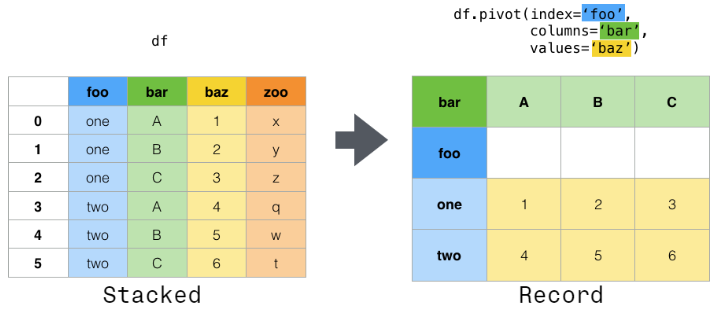

`pivot_table()` is used for pivoting with aggregation of numeric data (`values` is a numeric column).

For example, use file `cars2.csv`.

In [ ]:
df = pd.read_csv('cars2.csv')

In [ ]:
df.head()

<div class="alert alert-block alert-warning">
<b>Example: </b>Calculate mean horse power for each cylinder and each origin. Add total summary by rows and columns.
</div>

In [ ]:
df.pivot_table(values='Horsepower', index='Cylinders', columns='Origin', aggfunc=np.mean)

In [ ]:
df.pivot_table(values='Horsepower', index='Cylinders', columns='Origin', aggfunc=np.mean, margins=True)

<div class="alert alert-block alert-warning">
<b>Example: </b>Count cylinders of different origins.
</div>

In [ ]:
df[['Cylinders', 'Origin']].pivot_table(index='Cylinders', columns='Origin', aggfunc=len)

Missing values can be filled with pre-defined value (zero in this example):

In [ ]:
df[['Cylinders', 'Origin']].pivot_table(index='Cylinders', columns='Origin', aggfunc=len, fill_value=0)

In [ ]:
pt = df[['Cylinders', 'Origin']].pivot_table(index='Cylinders', columns='Origin', aggfunc=len, fill_value=0)
type(pt)